| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_2_GPU.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_4_Scientific_computing.ipynb) |

# 18.3 COMPUTACIÓN PARALELA

Paralelizar significa repartir trabajo que puede realizarse de forma simultánea. En ciencia computacional hay dos patrones frecuentes: resolver muchos problemas independientes, como un estudio de incertidumbre, y dividir un problema grande, como una PDE espacial. En ambos casos importan dependencias, memoria y comunicación.

Este cuaderno utiliza `ThreadPoolExecutor`, que funciona dentro de Jupyter sin necesitar que funciones definidas en una celda se serialicen para procesos. Es una elección docente: los hilos pueden aprovechar operaciones NumPy que liberan el GIL, pero no garantizan aceleración. Los tiempos se medirán en el equipo actual.

**Objetivos.** Identificar tareas independientes, construir semillas reproducibles, medir escalabilidad y reconocer el efecto del orden de reducción. Bibliotecas: NumPy, Matplotlib y biblioteca estándar. No hay archivos ni datasets externos.

## 1. Paralelismo de tareas y de datos

**Tareas independientes:** distintas tasas de difusión, semillas de entrenamiento o condiciones iniciales pueden resolverse sin intercambiar resultados intermedios. **Descomposición de dominio:** cada subdominio de una PDE depende de sus vecinos en la frontera. **Paralelismo de datos en ML:** minibatches se reparten y sus gradientes se combinan.

Una tarea no debe modificar datos compartidos sin sincronización. En nuestras simulaciones cada tarea tendrá su propio generador aleatorio y devolverá su propio resultado; el hilo principal construirá la colección. Esto evita carreras y hace clara la asociación entre entrada y salida.

## 2. El GIL y por qué elegimos hilos aquí

En CPython, el GIL limita ejecución simultánea de muchas operaciones de bytecode Python. Un bucle puramente Python puede no mejorar con hilos. NumPy suele ejecutar operaciones numéricas en código compilado que puede liberar ese bloqueo, aunque el comportamiento depende de operación y configuración.

Los procesos tienen intérpretes separados y pueden ser útiles para trabajo Python, pero añaden serialización y memoria. En Jupyter, `ProcessPoolExecutor` con una función creada en una celda puede fallar según el método de inicio; usar hilos evita ese problema en esta demostración. Para procesos en un proyecto, coloca tareas importables en un módulo y prueba explícitamente el mecanismo de inicio.

Más paralelismo no significa menos tiempo si se lanzan tareas demasiado pequeñas, se satura ancho de banda o cada operación interna ya usa varios hilos.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from time import perf_counter
import math, os
plt.rcParams.update({"figure.figsize": (8, 4), "axes.grid": True, "font.size": 11})
print("Núcleos lógicos reportados:", os.cpu_count())
print("Usaremos como máximo cuatro hilos, con resultados medidos localmente.")

Núcleos lógicos reportados: 16
Usaremos como máximo cuatro hilos, con resultados medidos localmente.


## 3. Experimento científico: conjuntos de difusión

Para $u_t=\alpha u_{xx}$ en $[0,2\pi)$, tomamos
$$u_0(x)=\sum_{m=1}^4 a_m\sin(mx),\qquad u(x,t)=\sum_{m=1}^4a_m e^{-\alpha m^2t}\sin(mx).$$
Muestrearemos $\alpha\sim U(0.05,0.35)$ y amplitudes $a_m$ alrededor de valores nominales. La cantidad de interés es la energía promedio $E(t)=\frac12\langle u^2\rangle_x$.

Por ortogonalidad de senos, una referencia exacta es $E(t)=\frac14\sum_ma_m^2e^{-2\alpha m^2t}$. La malla periódica sin duplicar el extremo integra exactamente estos modos discretos con la media muestral. Así podemos verificar el cálculo físico independientemente de su ejecución paralela.

In [2]:
x = 2*np.pi*np.arange(192)/192
modos = np.arange(1, 5)
basis = np.sin(modos[:, None]*x[None, :])
nominal = np.array([1.0, 0.35, 0.20, 0.10])
tiempos_fisicos = np.linspace(0, 3, 16)
# Cada tarea recibe una semilla distinta derivada de una raíz fija.
num_tareas, por_tarea = 24, 128
semillas = np.random.SeedSequence(183).spawn(num_tareas)

def simular_lote(semilla):
    rr = np.random.default_rng(semilla)
    alpha = rr.uniform(0.05, 0.35, por_tarea)
    amplitudes = rr.normal(nominal, 0.05, size=(por_tarea, 4))
    coef = amplitudes[:, None, :]*np.exp(-alpha[:, None, None]*tiempos_fisicos[None, :, None]*modos[None, None, :]**2)
    campo = np.einsum("btm,mx->btx", coef, basis, optimize=True)
    energia = 0.5*np.mean(campo*campo, axis=-1)
    referencia = 0.25*np.sum(coef*coef, axis=-1)
    if not np.allclose(energia, referencia, rtol=1e-12, atol=1e-12):
        raise ValueError("La energía calculada no coincide con la referencia espectral")
    return alpha, energia

serial = [simular_lote(s) for s in semillas]
alphas = np.concatenate([r[0] for r in serial])
energias = np.concatenate([r[1] for r in serial])
print("Realizaciones físicas:", len(alphas))
print("Energía media inicial y final:", energias[:, 0].mean(), energias[:, -1].mean())
assert np.all(np.diff(energias, axis=1) <= 1e-12)

Realizaciones físicas: 3072
Energía media inicial y final: 0.29682836424969095 0.08698149225164442


## 4. Semillas que no dependen del orden de ejecución

Si todos los hilos usan un generador global, el orden en que llegan las llamadas puede cambiar qué muestra recibe cada tarea. Aquí `SeedSequence.spawn` asigna una semilla a cada índice. Al crear de nuevo un generador a partir de esa semilla, la tarea recibe la misma entrada aunque cambie el número de trabajadores.

Esto permite comparar implementaciones con exactamente los mismos escenarios. No implica que las simulaciones sean físicamente independientes si hemos elegido un modelo con entradas dependientes; simplemente evita que el planificador cambie el diseño de muestreo.

`executor.map` preserva el orden de resultados según las entradas, aunque las tareas terminen en otro orden. Si utilizamos `as_completed`, tendremos que guardar además el índice de cada tarea.

Mismos parámetros y energías en serial y cuatro hilos.


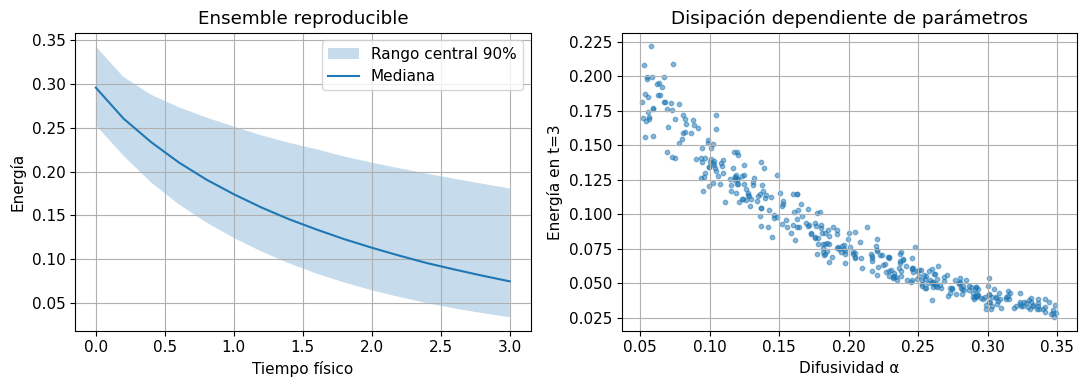

In [3]:
def ejecutar(workers):
    if workers == 1:
        return [simular_lote(s) for s in semillas]
    with ThreadPoolExecutor(max_workers=workers) as executor:
        return list(executor.map(simular_lote, semillas))

paralelo = ejecutar(4)
for esperado, calculado in zip(serial, paralelo):
    assert np.array_equal(esperado[0], calculado[0])
    assert np.allclose(esperado[1], calculado[1], rtol=1e-12, atol=1e-12)
print("Mismos parámetros y energías en serial y cuatro hilos.")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
lo, med, hi = np.quantile(energias, [0.05, 0.5, 0.95], axis=0)
axes[0].fill_between(tiempos_fisicos, lo, hi, alpha=0.25, label="Rango central 90%")
axes[0].plot(tiempos_fisicos, med, label="Mediana")
axes[0].set(xlabel="Tiempo físico", ylabel="Energía", title="Ensemble reproducible"); axes[0].legend()
axes[1].scatter(alphas[::8], energias[::8, -1], s=10, alpha=0.5)
axes[1].set(xlabel="Difusividad α", ylabel="Energía en t=3", title="Disipación dependiente de parámetros")
plt.tight_layout(); plt.show()

## 5. Medir speedup y eficiencia

Para un problema fijo, $S(p)=T(1)/T(p)$ y eficiencia $\eta(p)=S(p)/p$. Una eficiencia cercana a uno implica uso ideal de recursos; puede bajar por overhead, competencia por memoria, desbalance y partes seriales.

Mediremos mediana de tres repeticiones con creación del pool incluida. Ese costo pertenece al uso que hacemos aquí; una aplicación con pool persistente tendría otro perfil. Primero validamos resultados y después comparamos tiempo. El problema puede ser demasiado pequeño para ganar con cuatro hilos: ese resultado también enseña algo.

Tiempos medianos: {1: np.float64(0.04310071800136939), 2: np.float64(0.03515402699849801), 4: np.float64(0.04323098399981973)}


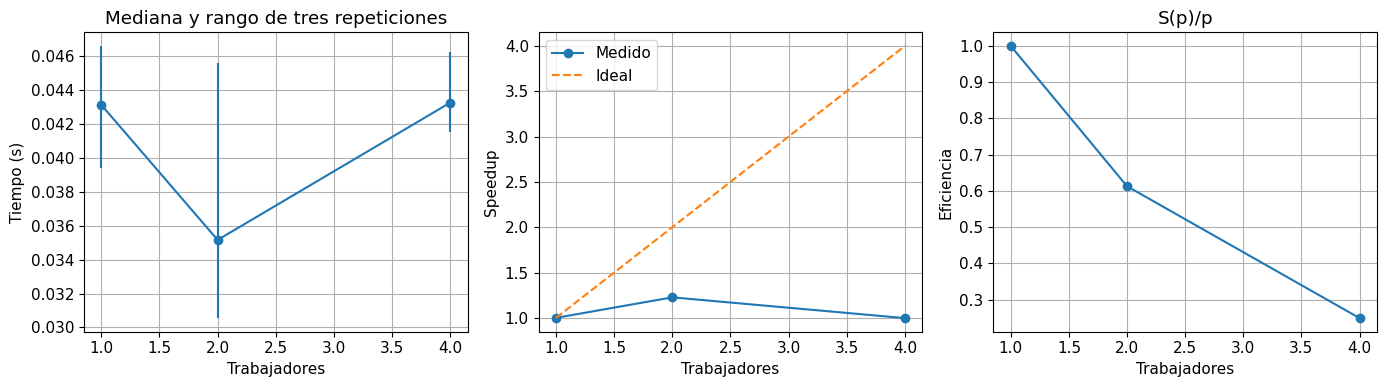

In [4]:
workers_lista = [1, 2, 4]
medianas, minimos, maximos = [], [], []
for workers in workers_lista:
    ejecutar(workers)  # Calentamiento.
    muestras = []
    for _ in range(3):
        inicio = perf_counter(); ejecutar(workers); muestras.append(perf_counter()-inicio)
    medianas.append(np.median(muestras)); minimos.append(min(muestras)); maximos.append(max(muestras))
medianas = np.array(medianas)
speedup = medianas[0]/medianas
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].errorbar(workers_lista, medianas, yerr=[medianas-np.array(minimos), np.array(maximos)-medianas], fmt="o-")
axes[0].set(xlabel="Trabajadores", ylabel="Tiempo (s)", title="Mediana y rango de tres repeticiones")
axes[1].plot(workers_lista, speedup, "o-", label="Medido")
axes[1].plot(workers_lista, workers_lista, "--", label="Ideal")
axes[1].set(xlabel="Trabajadores", ylabel="Speedup"); axes[1].legend()
axes[2].plot(workers_lista, speedup/np.array(workers_lista), "o-")
axes[2].set(xlabel="Trabajadores", ylabel="Eficiencia", title="S(p)/p")
plt.tight_layout(); plt.show()
print("Tiempos medianos:", dict(zip(workers_lista, medianas)))

## 6. No confundir curvas teóricas con mediciones

La ley de Amdahl supone una fracción serial $s$ y paralelización ideal del resto:
$$S(p)=\frac1{s+(1-s)/p}.$$
La curva siguiente ilustra supuestos elegidos; **no es un ajuste a las mediciones anteriores**. En realidad, costo de lanzar hilos, tareas pequeñas y ancho de banda pueden producir incluso $S(p)<1$.

La weak scaling aumenta el tamaño del problema a medida que crecen los recursos. No se puede llamar weak scaling a resolver exactamente las mismas 3072 realizaciones con más hilos. Tampoco hay que interpretar núcleos lógicos como si fueran núcleos físicos independientes.

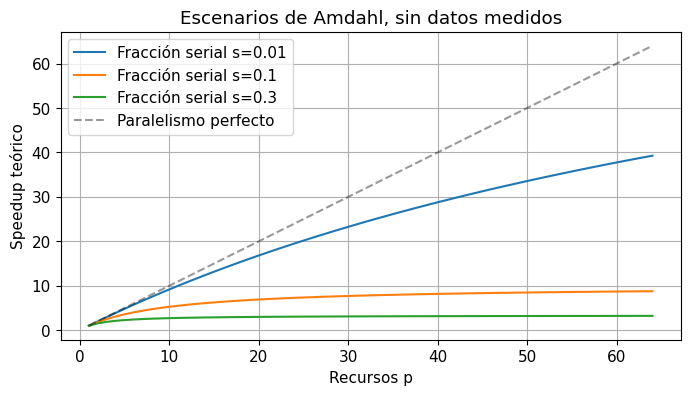

In [5]:
p = np.arange(1, 65)
fig, ax = plt.subplots()
for fraccion in [0.01, 0.1, 0.3]:
    ideal = 1/(fraccion+(1-fraccion)/p)
    ax.plot(p, ideal, label=f"Fracción serial s={fraccion}")
ax.plot(p, p, "k--", alpha=0.4, label="Paralelismo perfecto")
ax.set(xlabel="Recursos p", ylabel="Speedup teórico", title="Escenarios de Amdahl, sin datos medidos")
ax.legend(); plt.show()

## 7. Granularidad, balance y sobresuscripción

Muchísimas tareas diminutas pueden dedicar más tiempo al planificador que al cálculo. Agrupar realizaciones en lotes reduce overhead, pero lotes enormes pueden crear desbalance: un trabajador queda ocupado mientras los demás esperan. En un solver adaptativo, distintos parámetros pueden requerir números muy distintos de pasos.

Algunas rutinas de NumPy llaman bibliotecas BLAS con su propio conjunto de hilos. Cuatro trabajadores externos por ocho hilos internos pueden lanzar 32 hilos para pocos núcleos. Este cuaderno no modifica variables globales del entorno del usuario; al hacer un benchmark formal documenta los límites de hilos utilizados y la biblioteca numérica.

## 8. Reducciones y aritmética no asociativa

En números reales, $(a+b)+c=a+(b+c)$. En punto flotante puede fallar. Una suma paralela agrupa términos en otro orden y puede cambiar los últimos bits o perder contribuciones pequeñas frente a números enormes. Fijar una semilla no controla ese orden.

`math.fsum` ofrece una suma compensada de alta precisión para datos Python. También existen sumas por pares y Kahan. No toda diferencia pequeña indica una carrera: primero considera tolerancias, escalas y estabilidad de la reducción. Si se exige reproducibilidad binaria, puede haber un costo adicional.

In [6]:
valores = [1e16, 1.0, -1e16]
print("Suma en orden 1:", sum(valores))
print("Suma en orden 2:", sum([1e16, -1e16, 1.0]))
print("Suma robusta math.fsum:", math.fsum(valores))
# Reducción de la cantidad científica del ensemble, con orden estable de tareas.
medias_lotes = [r[1][:, -1].mean() for r in paralelo]
media_reducida = math.fsum(medias_lotes)/len(medias_lotes)
print("Media por reducción de lotes:", media_reducida)
assert np.isclose(media_reducida, energias[:, -1].mean(), rtol=1e-12)

Suma en orden 1: 0.0
Suma en orden 2: 1.0
Suma robusta math.fsum: 1.0
Media por reducción de lotes: 0.08698149225164442


## 9. Descomposición espacial y celdas halo

Para calor periódico con diferencias finitas explícitas,
$$u_i^{n+1}=u_i^n+r(u_{i-1}^n-2u_i^n+u_{i+1}^n),\qquad r=\alpha\Delta t/\Delta x^2.$$
Cada subdominio necesita un valor vecino a cada lado: esas son celdas halo. Todos los subdominios deben leer del **estado anterior**, no de un arreglo que ya están actualizando. Para este esquema 1D, estabilidad exige $r\le1/2$.

La siguiente demostración divide el arreglo en cuatro partes y reconstruye halos periódicos. Simula la lógica de descomposición en un único proceso; **no mide comunicación MPI ni speedup distribuido**. Su propósito es verificar la dependencia que luego implementaría un programa distribuido.

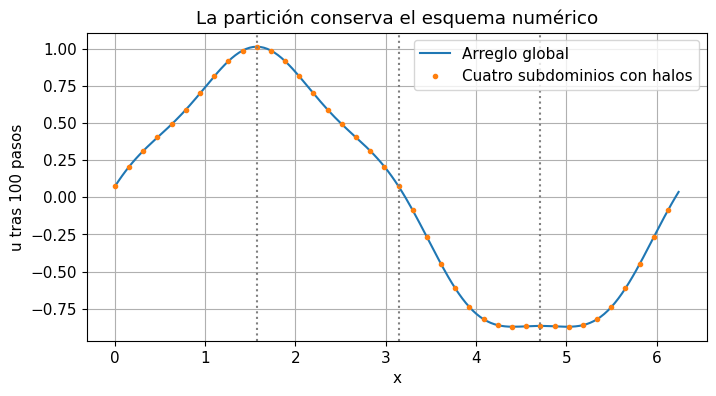

In [7]:
Nesp, r, pasos = 160, 0.4, 100
xx = 2*np.pi*np.arange(Nesp)/Nesp
u_serial = np.sin(xx)+0.2*np.cos(4*xx)
u_partido = u_serial.copy()
indices = np.array_split(np.arange(Nesp), 4)

def paso_global(u):
    return u+r*(np.roll(u, 1)-2*u+np.roll(u, -1))

def paso_con_halos(u):
    salida = np.empty_like(u)
    for idx in indices:
        halo = np.r_[u[(idx[0]-1) % len(u)], u[idx], u[(idx[-1]+1) % len(u)]]
        salida[idx] = halo[1:-1]+r*(halo[:-2]-2*halo[1:-1]+halo[2:])
    return salida

for _ in range(pasos):
    u_serial = paso_global(u_serial); u_partido = paso_con_halos(u_partido)
assert np.allclose(u_serial, u_partido, atol=1e-13)
fig, ax = plt.subplots()
ax.plot(xx, u_serial, label="Arreglo global")
ax.plot(xx[::4], u_partido[::4], "o", ms=3, label="Cuatro subdominios con halos")
for idx in indices[1:]: ax.axvline(xx[idx[0]], color="gray", ls=":")
ax.set(xlabel="x", ylabel="u tras 100 pasos", title="La partición conserva el esquema numérico")
ax.legend(); plt.show()

## 10. Comunicación y escalabilidad de una PDE

Al dividir una malla, el volumen de trabajo local disminuye, mientras la frontera comunicada puede hacerse relativamente más importante. En 2D, un bloque de lado $n$ tiene $O(n^2)$ interior y $O(n)$ frontera. Cuando cada trabajador recibe pocos puntos, latencia y sincronización pueden dominar.

MPI expresa intercambio entre procesos y máquinas; una reducción global se usa para normas, criterios de convergencia o gradientes. El solapamiento de comunicación con trabajo interior puede ayudar, pero requiere cuidar dependencias y buffers. En este cuaderno no necesitamos instalar MPI para comprender y verificar el stencil.

## 11. Relación con SciML

Los ensembles de incertidumbre y búsquedas de hiperparámetros permiten paralelismo de tareas. El entrenamiento por datos requiere combinar gradientes; el entrenamiento por modelo reparte capas o estados. Un neural operator en varias GPUs introduce comunicación distinta de una PDE por subdominios.

Una comparación debe considerar solver de referencia, número de realizaciones, error, costo de comunicación y generación de datos. Paralelizar un método incorrecto produce respuestas incorrectas más rápido; por eso usamos energía exacta y un esquema global como referencias.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../18_HPC_COMPUTACION_CIENTIFICA/18_2_GPU.ipynb) | [⏩](../18_HPC_COMPUTACION_CIENTIFICA/18_4_Scientific_computing.ipynb) |